# Prompt Guard: Milestone 2B, Linear SVM

**Question.** Does a different learning rule on the **same features** work better than Logistic Regression?

A **Linear SVM** (Support Vector Machine) uses exactly the same TF-IDF character pieces as our TF-IDF model.
The difference is how it learns: Logistic Regression learns probabilities, the SVM looks for the boundary between
the classes with the **largest safety distance** (margin) to the training texts. For text with many features this
is often a bit more accurate, and training is fast.

**Setup, mirroring our TF-IDF steps** (one change per step, so we know where a difference comes from):

| Part | Training data | Comparable with |
|---|---|---|
| **A. SVM tuned** | ai4privacy train only; we tune `C` and the block threshold | `tfidf_tuning.ipynb` |
| **B. SVM + harmless prompts** | ai4privacy train + harmless prompts (`src/harmless_data.py`), `C` from part A | `tfidf_harmless.ipynb` |

At the end, **chapter 9 compares all four models** (TF-IDF tuned, TF-IDF + harmless, SVM tuned, SVM + harmless)
on the same validation data and our 200 own prompts.

**Same as before:** split (`data/splits.csv`), policy (`config/policy.yaml`), TF-IDF settings, metrics, MLflow
metric names, and the rule for choosing the threshold.

**Rules:** train only on train, choose settings on validation, never touch a test set, only look at our own prompts.

**Structure**
1. Setup · 2. Load the data · 3. Helper functions · 4. Part A: train `C` · 5. Part A: block threshold ·
6. Part A: save and log · 7. Part B: SVM + harmless prompts · 8. Part B: save and log ·
9. Comparison of all models · 10. Own prompts the best model gets wrong · 11. Conclusion

**Before the first run:** `python src/harmless_data.py` (the fingerprint must match the README).
For chapter 9, `tfidf_tuning.ipynb` and `tfidf_harmless.ipynb` must have been run once (their model files are loaded).
With 8 GB RAM, run only this notebook and close the others.

## 1. Setup

Same settings as in the TF-IDF notebooks. New is `LinearSVC` from scikit-learn.

In [1]:
import os
import sys
import gc
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import joblib
import mlflow

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score, recall_score

sys.path.append("../src")
from data_utils import load_all_splits, split_fingerprint
from harmless_data import load_harmless, harmless_fingerprint

SEED = 42
CLASSES = ["allow", "warn", "block"]
PROJECT_DIR = Path("..").resolve()
MODEL_DIR = PROJECT_DIR / "models"

TARGET_RECALL_BLOCK = 0.95       # at least 95 % of block texts must be blocked
TARGET_FALSE_BLOCK = 0.05        # at most 5 % of harmless (allow) texts may be blocked

# Exactly the same TF-IDF settings as in all TF-IDF notebooks
TFIDF_PARAMS = dict(analyzer="char_wb", ngram_range=(2, 5), min_df=5, max_features=300_000,
                    sublinear_tf=True, dtype=np.float32)

with open(PROJECT_DIR / "config" / "policy.yaml", encoding="utf-8") as f:
    POLICY_VERSION = str(yaml.safe_load(f)["version"])

BLUE = "#2a78d6"
ORANGE = "#eb6834"
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# MLflow: shared DagsHub server if MLFLOW_TRACKING_URI is set in .env, otherwise local
try:
    from dotenv import load_dotenv
    load_dotenv(PROJECT_DIR / ".env")
except ImportError:
    pass
if os.getenv("MLFLOW_TRACKING_URI"):
    mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
    if mlflow.get_experiment_by_name("promptguard") is None:
        mlflow.create_experiment("promptguard")
else:
    mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_DIR / 'mlflow.db').as_posix()}")
    if mlflow.get_experiment_by_name("promptguard") is None:
        mlflow.create_experiment("promptguard", artifact_location=(PROJECT_DIR / "mlruns").as_uri())
mlflow.set_experiment("promptguard")
print("Policy version:", POLICY_VERSION, "| MLflow:", mlflow.get_tracking_uri())

c:\Users\olga9\Desktop\Studium Heilbronn\Kurse\WiSe26\AIO - AI Operations\AIOps_PromptGuard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Policy version: 0.1 | MLflow: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow


## 2. Load the data

Same as in `tfidf_harmless.ipynb`: ai4privacy and the harmless prompts in one table, with a column `origin`.
Part A uses only the ai4privacy rows for training, part B uses all rows.
Validation always contains both, so every model is measured on the same texts.

In [2]:
splits = load_all_splits()
pii_train, pii_val = splits["train"], splits["validation"]
del splits                                     # no test set in this notebook

harmless_train = load_harmless("train")
harmless_val = load_harmless("validation")     # we deliberately do not load the test part

SPLIT_FINGERPRINT = split_fingerprint()
HARMLESS_FINGERPRINT = harmless_fingerprint()
print("Split fingerprint:   ", SPLIT_FINGERPRINT)
print("Harmless fingerprint:", HARMLESS_FINGERPRINT)

COLUMNS = ["source_text", "decision", "language"]

def tag(df, origin):
    # keep only the columns we need and add where the text comes from
    return df[COLUMNS].assign(origin=origin)

train = pd.concat([tag(pii_train, "ai4privacy"), tag(harmless_train, "harmless")], ignore_index=True)
val = pd.concat([tag(pii_val, "ai4privacy"), tag(harmless_val, "harmless")], ignore_index=True)
own = pd.read_csv(PROJECT_DIR / "data" / "own_prompts.csv")

# The full ai4privacy tables are no longer needed (saves a lot of memory)
del pii_train, pii_val
_ = gc.collect()

is_pii_train = (train["origin"] == "ai4privacy").to_numpy()
is_pii = (val["origin"] == "ai4privacy").to_numpy()      # validation rows from ai4privacy
is_harmless = ~is_pii                                     # validation rows from the harmless prompts
is_de = (val["language"] == "de").to_numpy()

display(pd.crosstab(train["origin"], train["decision"], margins=True).rename_axis("TRAIN"))
display(pd.crosstab(val["origin"], val["decision"], margins=True).rename_axis("VALIDATION"))

Split fingerprint:    6afd6a257de1
Harmless fingerprint: 32d24c900fd7


decision,allow,block,warn,All
TRAIN,,,,
ai4privacy,11471,46056,88928,146455
harmless,3864,0,0,3864
All,15335,46056,88928,150319


decision,allow,block,warn,All
VALIDATION,,,,
ai4privacy,2457,9868,19055,31380
harmless,557,0,0,557
All,3014,9868,19055,31937


## 3. Helper functions

**The SVM gives scores, not probabilities.** For every prompt it gives one score per class
(`decision_function`): the higher, the more sure. A score around 0 means "on the boundary".
So our block rule becomes:

> **If the block score is at least `t`, the prompt is blocked.** Otherwise the higher of allow and warn wins.

With the default rule (highest score wins) a prompt is blocked when its block score is the highest.
A lower `t` (for example -0.3) blocks more prompts, just like a lower probability threshold did for TF-IDF.

`evaluate` and `harmless_shares` are the same functions as in `tfidf_harmless.ipynb`.
`model_scores` works for both model types, so chapter 9 can compare TF-IDF and SVM with the same code.

In [3]:
def model_scores(pipe, texts):
    # SVM -> decision_function (scores), Logistic Regression -> predict_proba (probabilities)
    if hasattr(pipe, "decision_function") and not hasattr(pipe, "predict_proba"):
        return pipe.decision_function(texts)
    return pipe.predict_proba(texts)


def predict_with_threshold(scores, classes, threshold):
    classes = list(classes)
    if threshold is None:                      # default rule: highest score wins
        return np.array(classes)[scores.argmax(axis=1)]
    s_block = scores[:, classes.index("block")]
    other = [c for c in classes if c != "block"]
    best_other = np.array(other)[scores[:, [classes.index(c) for c in other]].argmax(axis=1)]
    return np.where(s_block >= threshold, "block", best_other)


def evaluate(y_true, y_pred) -> dict:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    is_allow, is_warn = y_true == "allow", y_true == "warn"
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "recall_block": recall_score(y_true, y_pred, labels=["block"], average="macro", zero_division=0),
        "recall_warn": recall_score(y_true, y_pred, labels=["warn"], average="macro", zero_division=0),
        "recall_allow": recall_score(y_true, y_pred, labels=["allow"], average="macro", zero_division=0),
        "false_block_allow": float((y_pred[is_allow] == "block").mean()) if is_allow.any() else np.nan,
        "false_block_warn": float((y_pred[is_warn] == "block").mean()) if is_warn.any() else np.nan,
    }


def harmless_shares(y_pred) -> dict:
    y_pred = np.asarray(y_pred)
    return {f"harmless -> {c}": float((y_pred == c).mean()) for c in CLASSES}


# Thresholds we try on the block SCORE (from strict to generous)
# If the chosen threshold is the first or the last value of this list, the best value may lie outside:
# then extend the list (e.g. down to -1.5) and run again.
THRESHOLDS = [0.5, 0.4, 0.3, 0.2, 0.1, 0.0, -0.1, -0.2, -0.3, -0.4, -0.5, -0.6, -0.7, -0.8, -1.0]


def threshold_sweep(scores, classes, y_true, rows_mask):
    # tries every threshold on the given rows and returns one table row per threshold
    rows = []
    for t in THRESHOLDS:
        pred = predict_with_threshold(scores[rows_mask], classes, t)
        rows.append({"threshold": t, **evaluate(np.asarray(y_true)[rows_mask], pred)})
    sweep = pd.DataFrame(rows)
    sweep["meets both targets"] = ((sweep["recall_block"] >= TARGET_RECALL_BLOCK)
                                   & (sweep["false_block_allow"] <= TARGET_FALSE_BLOCK))
    return sweep


def choose_threshold(sweep):
    # The same rule as in the TF-IDF notebooks, written down before looking at the results:
    # 1. highest threshold that reaches both targets, otherwise
    # 2. best recall block among thresholds with <= 5 % harmless texts blocked
    both = sweep[sweep["meets both targets"]]
    if len(both):
        return float(both["threshold"].max()), "highest threshold that reaches both targets"
    safe = sweep[sweep["false_block_allow"] <= TARGET_FALSE_BLOCK]
    if len(safe):
        return float(safe.loc[safe["recall_block"].idxmax(), "threshold"]), \
            "both targets not reachable; best recall block with <= 5 % false alarms"
    return None, "no threshold keeps false alarms <= 5 %; keep the default rule"


def plot_sweep(sweep, title):
    fig, ax = plt.subplots()
    ax.plot(sweep["threshold"], sweep["recall_block"], marker="o", color=BLUE, label="recall block (higher = safer)")
    ax.plot(sweep["threshold"], sweep["false_block_allow"], marker="o", color=ORANGE, label="allow texts blocked (lower = better)")
    ax.axhline(TARGET_RECALL_BLOCK, color=BLUE, linestyle="--", linewidth=1)
    ax.axhline(TARGET_FALSE_BLOCK, color=ORANGE, linestyle="--", linewidth=1)
    ax.invert_xaxis()
    ax.set_xlabel("block threshold t on the SVM score")
    ax.set_ylabel("share")
    ax.set_title(title)
    ax.legend(loc="center right")
    plt.tight_layout()
    plt.show()


def train_svm(X, y, C):
    # LinearSVC, the same class_weight as LogReg; returns the model and whether it converged
    model = LinearSVC(C=C, class_weight="balanced", max_iter=5000, random_state=SEED)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        start = time.perf_counter()
        model.fit(X, y)
        seconds = time.perf_counter() - start
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return model, converged, seconds


def common_params(C, threshold):
    return {"model": "tfidf_linearsvc", "analyzer": "char_wb", "ngram_range": "2-5", "min_df": 5,
            "max_features": 300_000, "C": C, "class_weight": "balanced", "max_iter": 5000,
            "block_threshold": "argmax" if threshold is None else threshold,
            "split_fingerprint": SPLIT_FINGERPRINT, "policy_version": POLICY_VERSION}

## 4. Part A: train the SVM and choose `C` (ai4privacy only)

We turn the texts into numbers exactly like in `tfidf_tuning.ipynb` (vectorizer fitted on ai4privacy train only)
and try three values of `C`. For the SVM, good values of `C` are usually **smaller** than for Logistic Regression,
because the two models use `C` on a different scale. Each value becomes its own MLflow run.

**How we choose:** best macro F1 on ai4privacy validation; if two values are within 0.002, the smaller one.

In [4]:
vec_a = TfidfVectorizer(**TFIDF_PARAMS)
start = time.perf_counter()
Xa_train = vec_a.fit_transform(train["source_text"][is_pii_train])
ya_train = train["decision"][is_pii_train]
Xa_val = vec_a.transform(val["source_text"])          # all validation rows (ai4privacy + harmless)
print(f"Vectorising took {time.perf_counter() - start:.0f} s, matrix: {Xa_train.shape}")

C_VALUES = [0.1, 0.3, 1.0]
results, models_a = [], {}
for C in C_VALUES:
    model, converged, seconds = train_svm(Xa_train, ya_train, C)
    models_a[C] = model
    pred = model.predict(Xa_val[is_pii])
    m = evaluate(val["decision"][is_pii], pred)
    results.append({"C": C, **m, "converged": converged, "training time (s)": round(seconds)})
    with mlflow.start_run(run_name=f"svm_C{C}"):
        mlflow.set_tags({"milestone": "M2", "experiment_part": "B_svm_tune_C"})
        mlflow.log_params(common_params(C, None))
        mlflow.log_metrics({f"val_{k}": v for k, v in m.items()})
        mlflow.log_metric("converged", int(converged))
    print(f"C={C}: recall block {m['recall_block']:.3f}, macro F1 {m['macro_f1']:.3f}, {seconds:.0f} s")

c_results = pd.DataFrame(results).set_index("C").round(4)
display(c_results)

best_f1 = c_results["macro_f1"].max()
BEST_C = float(c_results.index[c_results["macro_f1"] >= best_f1 - 0.002].min())
svm_a = models_a[BEST_C]
print("Chosen C:", BEST_C)

Vectorising took 142 s, matrix: (146455, 300000)
🏃 View run svm_C0.1 at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/c5554d68ea88419283ad4089d1497dd8
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
C=0.1: recall block 0.885, macro F1 0.852, 26 s
🏃 View run svm_C0.3 at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/6e447e24cd154f4d9ae6b21a737a0526
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
C=0.3: recall block 0.901, macro F1 0.870, 34 s
🏃 View run svm_C1.0 at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/2b4efb55be9b405bb4965642a6f78dde
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
C=1.0: recall block 0.912, macro F1 0.880, 50 s


,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,converged,training time (s)
C,,,,,,,,
0.1,0.8517,0.8852,0.9281,0.7802,0.0147,0.0276,True,26
0.3,0.8701,0.9012,0.9334,0.8120,0.0102,0.0284,True,34
1.0,0.8796,0.9118,0.9378,0.8095,0.0102,0.0306,True,50


Chosen C: 1.0


## 5. Part A: block threshold

Same idea as in `tfidf_tuning.ipynb`, chosen on **ai4privacy validation** (so it is comparable with the TF-IDF
tuning). The first row is the default rule.

,threshold,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,meets both targets
0,argmax (default),0.8796,0.9118,0.9378,0.8095,0.0102,0.0306,NaN
1,0.5,0.8502,0.7897,0.9614,0.8152,0.0033,0.0044,False
2,0.4,0.8587,0.8173,0.9595,0.8148,0.0037,0.0064,False
3,0.3,0.8652,0.8415,0.9574,0.8132,0.0053,0.0088,False
4,0.2,0.8705,0.8626,0.9543,0.8120,0.0069,0.0119,False
5,0.1,0.8761,0.8864,0.9498,0.8112,0.0077,0.0168,False
6,0.0,0.8784,0.9039,0.9442,0.8087,0.0102,0.0226,False
7,-0.1,0.8784,0.9181,0.9362,0.8046,0.0151,0.0310,False
8,-0.2,0.8764,0.9329,0.9258,0.7977,0.0220,0.0417,False
9,-0.3,0.8719,0.9449,0.9123,0.7871,0.0330,0.0563,False


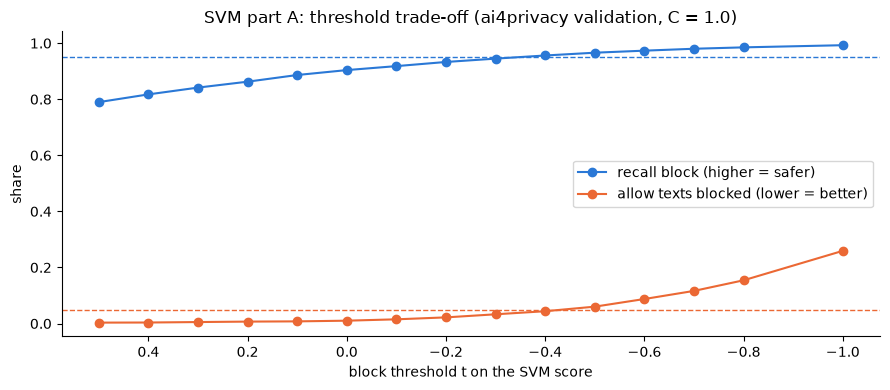

Chosen threshold: -0.4 (highest threshold that reaches both targets)


,ai4privacy validation
macro_f1,0.8647
recall_block,0.9560
recall_warn,0.8938
recall_allow,0.7770
false_block_allow,0.0440
false_block_warn,0.0756


In [5]:
scores_a = svm_a.decision_function(Xa_val)
classes_a = svm_a.classes_

sweep_a = threshold_sweep(scores_a, classes_a, val["decision"], is_pii)
default_row = {"threshold": "argmax (default)",
               **evaluate(val["decision"][is_pii], predict_with_threshold(scores_a[is_pii], classes_a, None))}
display(pd.concat([pd.DataFrame([default_row]), sweep_a], ignore_index=True).round(4))
plot_sweep(sweep_a, f"SVM part A: threshold trade-off (ai4privacy validation, C = {BEST_C})")

THRESHOLD_A, reason_a = choose_threshold(sweep_a)
pred_a = predict_with_threshold(scores_a, classes_a, THRESHOLD_A)
metrics_a = evaluate(val["decision"][is_pii], pred_a[is_pii])
print(f"Chosen threshold: {THRESHOLD_A} ({reason_a})")
display(pd.Series(metrics_a).round(4).to_frame("ai4privacy validation"))

## 6. Part A: save and log

Saved as `models/svm_tuned.joblib`, in the same format as the TF-IDF models (pipeline + threshold), plus the
key `score = "decision_function"`, so the API later knows that the threshold is on the score scale.
Then we free the memory of part A before part B starts.

In [6]:
MODEL_DIR.mkdir(exist_ok=True)
pipe_a = Pipeline([("tfidf", vec_a), ("svm", svm_a)])
path_a = MODEL_DIR / "svm_tuned.joblib"
joblib.dump({"pipeline": pipe_a, "block_threshold": THRESHOLD_A, "score": "decision_function",
             "classes": list(classes_a), "split_fingerprint": SPLIT_FINGERPRINT,
             "policy_version": POLICY_VERSION}, path_a)

with mlflow.start_run(run_name="svm_tuned"):
    mlflow.set_tags({"milestone": "M2", "experiment_part": "B_svm_threshold", "candidate": "true"})
    mlflow.log_params({**common_params(BEST_C, THRESHOLD_A), "threshold_reason": reason_a})
    mlflow.log_metrics({f"val_{k}": v for k, v in metrics_a.items()})
    mlflow.log_metric("val_de_recall_block",
                      recall_score(val["decision"][is_pii & is_de], pred_a[is_pii & is_de], labels=["block"], average="macro"))
    mlflow.log_artifact(str(path_a))
print("Saved and logged:", path_a.name)

# free memory of part A
del Xa_train, Xa_val, ya_train, models_a, scores_a
_ = gc.collect()

🏃 View run svm_tuned at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/a0199bda94fc4302a19c49550adb3858
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
Saved and logged: svm_tuned.joblib


## 7. Part B: SVM + harmless prompts

Same as `tfidf_harmless.ipynb`, but with the SVM: the vectorizer is fitted on **all** train rows
(ai4privacy + harmless), `C` comes from part A, and the threshold is chosen again on the **combined** validation
set, so that `false_block_allow` also counts real harmless prompts.

Vectorising took 147 s, matrix: (150319, 300000)
Training took 47 s, converged: True


,threshold,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,meets both targets
0,0.5,0.8602,0.7925,0.9597,0.8324,0.0033,0.0043,False
1,0.4,0.8682,0.8191,0.9578,0.8318,0.0040,0.0063,False
2,0.3,0.8740,0.8423,0.9555,0.8301,0.0060,0.0087,False
3,0.2,0.8794,0.8642,0.9522,0.8291,0.0076,0.0123,False
4,0.1,0.8841,0.8863,0.9476,0.8281,0.0086,0.0173,False
5,0.0,0.8868,0.9047,0.9423,0.8261,0.0106,0.0229,False
6,-0.1,0.8865,0.9189,0.9343,0.8225,0.0153,0.0314,False
7,-0.2,0.8842,0.9329,0.9240,0.8155,0.0222,0.0421,False
8,-0.3,0.8799,0.9454,0.9101,0.8076,0.0309,0.0571,False
9,-0.4,0.8729,0.9567,0.8918,0.7979,0.0411,0.0764,True


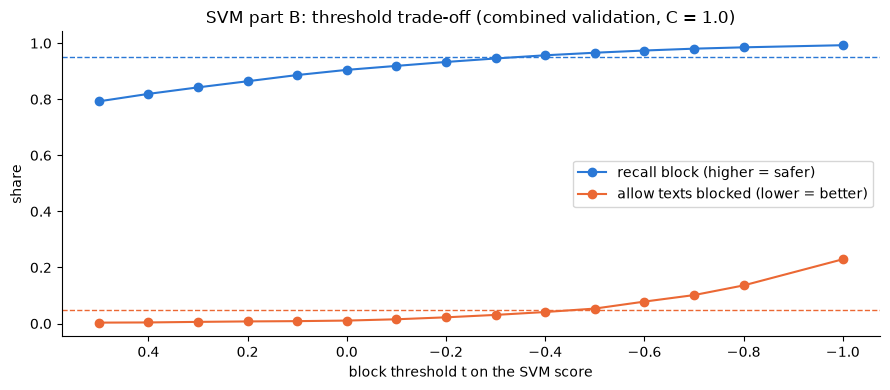

Chosen threshold: -0.4 (highest threshold that reaches both targets)


,combined validation
macro_f1,0.8729
recall_block,0.9567
recall_warn,0.8918
recall_allow,0.7979
false_block_allow,0.0411
false_block_warn,0.0764
harmless_to_block,0.0233
harmless_to_warn,0.0628


In [7]:
vec_b = TfidfVectorizer(**TFIDF_PARAMS)
start = time.perf_counter()
Xb_train = vec_b.fit_transform(train["source_text"])
Xb_val = vec_b.transform(val["source_text"])
print(f"Vectorising took {time.perf_counter() - start:.0f} s, matrix: {Xb_train.shape}")

svm_b, converged_b, seconds_b = train_svm(Xb_train, train["decision"], BEST_C)
print(f"Training took {seconds_b:.0f} s, converged: {converged_b}")

scores_b = svm_b.decision_function(Xb_val)
classes_b = svm_b.classes_
all_rows = np.ones(len(val), dtype=bool)
sweep_b = threshold_sweep(scores_b, classes_b, val["decision"], all_rows)
display(sweep_b.round(4))
plot_sweep(sweep_b, f"SVM part B: threshold trade-off (combined validation, C = {BEST_C})")

THRESHOLD_B, reason_b = choose_threshold(sweep_b)
pred_b = predict_with_threshold(scores_b, classes_b, THRESHOLD_B)
metrics_b = evaluate(val["decision"], pred_b)
metrics_b["harmless_to_block"] = float((pred_b[is_harmless] == "block").mean())
metrics_b["harmless_to_warn"] = float((pred_b[is_harmless] == "warn").mean())
print(f"Chosen threshold: {THRESHOLD_B} ({reason_b})")
display(pd.Series(metrics_b).round(4).to_frame("combined validation"))

## 8. Part B: save and log

In [8]:
pipe_b = Pipeline([("tfidf", vec_b), ("svm", svm_b)])
path_b = MODEL_DIR / "svm_harmless.joblib"
joblib.dump({"pipeline": pipe_b, "block_threshold": THRESHOLD_B, "score": "decision_function",
             "classes": list(classes_b), "split_fingerprint": SPLIT_FINGERPRINT,
             "harmless_fingerprint": HARMLESS_FINGERPRINT, "policy_version": POLICY_VERSION}, path_b)

with mlflow.start_run(run_name="svm_harmless"):
    mlflow.set_tags({"milestone": "M2", "experiment_part": "B_svm_harmless_data", "candidate": "true"})
    mlflow.log_params({**common_params(BEST_C, THRESHOLD_B), "threshold_reason": reason_b,
                       "harmless_fingerprint": HARMLESS_FINGERPRINT, "n_harmless_train": int((~is_pii_train).sum())})
    mlflow.log_metrics({f"val_{k}": v for k, v in metrics_b.items()})
    mlflow.log_metric("val_de_recall_block",
                      recall_score(val["decision"][is_de], pred_b[is_de], labels=["block"], average="macro"))
    mlflow.log_metric("converged", int(converged_b))
    mlflow.log_artifact(str(path_b))
print("Saved and logged:", path_b.name)

del Xb_train, Xb_val, scores_b
_ = gc.collect()

🏃 View run svm_harmless at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/d7208f169ad3452fbb3fea2de7543be0
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
Saved and logged: svm_harmless.joblib


## 9. Comparison of all models

All four saved models are measured with **the same code on the same data**: ai4privacy validation, the real
harmless validation prompts and our 200 own German prompts. Response time: 1,000 single prompts per model
on this laptop, so the times are fair to compare **within** this table.

Missing model files are skipped (run the TF-IDF notebooks first to see them here).

In [9]:
MODEL_FILES = {
    "TF-IDF + LogReg tuned": "tfidf_logreg_tuned.joblib",
    "TF-IDF + LogReg + harmless": "tfidf_logreg_harmless.joblib",
    "SVM tuned": "svm_tuned.joblib",
    "SVM + harmless": "svm_harmless.joblib",
}
expected = own["expected_decision"].to_numpy()
casual = (own["style"] == "casual").to_numpy()
latency_sample = val["source_text"].sample(1000, random_state=SEED).tolist()

columns, own_predictions = {}, {}
for name, filename in MODEL_FILES.items():
    path = MODEL_DIR / filename
    if not path.exists():
        print(f"skipped (file missing): {filename}")
        continue
    bundle = joblib.load(path)
    pipe, threshold = bundle["pipeline"], bundle["block_threshold"]
    classes = pipe.classes_

    val_pred = predict_with_threshold(model_scores(pipe, val["source_text"]), classes, threshold)
    own_pred = predict_with_threshold(model_scores(pipe, own["prompt"].tolist()), classes, threshold)
    own_predictions[name] = own_pred

    times = []
    for prompt in latency_sample:
        start = time.perf_counter()
        predict_with_threshold(model_scores(pipe, [prompt]), classes, threshold)
        times.append((time.perf_counter() - start) * 1000)

    pii = evaluate(val["decision"][is_pii], val_pred[is_pii])
    h = harmless_shares(val_pred[is_harmless])
    own_block = expected == "block"
    columns[name] = {
        "block threshold": threshold,
        "ai4privacy recall block": round(pii["recall_block"], 3),
        "ai4privacy recall block (de)": round(recall_score(val["decision"][is_pii & is_de], val_pred[is_pii & is_de],
                                                           labels=["block"], average="macro"), 3),
        "ai4privacy macro F1": round(pii["macro_f1"], 3),
        "ai4privacy allow texts blocked": round(pii["false_block_allow"], 3),
        "real harmless prompts allowed": f"{h['harmless -> allow']:.1%}",
        "real harmless prompts blocked": f"{h['harmless -> block']:.1%}",
        "own prompts correct": f"{(own_pred == expected).sum()} of {len(expected)}",
        "own: block prompts caught": f"{(own_pred[own_block] == 'block').sum()} of {own_block.sum()}",
        "own: casual block prompts caught": f"{(own_pred[own_block & casual] == 'block').sum()} of {(own_block & casual).sum()}",
        "own: harmless prompts blocked": f"{(own_pred[expected == 'allow'] == 'block').sum()} of {(expected == 'allow').sum()}",
        "own: warn prompts let through (allow)": f"{(own_pred[expected == 'warn'] == 'allow').sum()} of {(expected == 'warn').sum()}",
        "response time p95 (ms)": round(float(np.percentile(times, 95)), 1),
    }
    del bundle, pipe
    _ = gc.collect()

comparison = pd.DataFrame(columns)
display(comparison)

reports = PROJECT_DIR / "reports"
reports.mkdir(exist_ok=True)
comparison.to_csv(reports / "model_comparison_m2.csv")
print("Saved: reports/model_comparison_m2.csv")

,TF-IDF + LogReg tuned,TF-IDF + LogReg + harmless,SVM tuned,SVM + harmless
block threshold,0.2,0.2,-0.4,-0.4
ai4privacy recall block,0.955,0.953,0.956,0.957
ai4privacy recall block (de),0.953,0.944,0.955,0.956
ai4privacy macro F1,0.864,0.844,0.865,0.862
ai4privacy allow texts blocked,0.022,0.031,0.044,0.045
real harmless prompts allowed,41.1%,93.2%,28.2%,91.4%
real harmless prompts blocked,4.5%,1.8%,4.1%,2.3%
own prompts correct,130 of 200,155 of 200,127 of 200,156 of 200
own: block prompts caught,56 of 60,55 of 60,57 of 60,56 of 60
own: casual block prompts caught,12 of 15,13 of 15,12 of 15,12 of 15


Saved: reports/model_comparison_m2.csv


In [13]:
# Log the results of the comparison (chapter 9) also to the two SVM runs in MLflow,
# with the same metric names as in the TF-IDF runs, so all models can be compared in DagsHub.
comparison_csv = pd.read_csv(PROJECT_DIR / "reports" / "model_comparison_m2.csv", index_col=0)

def share(text):
    # "156 of 200" -> 0.78
    hit, total = str(text).split(" of ")
    return int(hit) / int(total)

for column, run_name in [("SVM tuned", "svm_tuned"), ("SVM + harmless", "svm_harmless")]:
    if column not in comparison_csv.columns:
        print("not in the comparison table:", column)
        continue
    # the newest run with this name in our experiment
    runs = mlflow.search_runs(filter_string=f"tags.mlflow.runName = '{run_name}'",
                              order_by=["attributes.start_time DESC"], max_results=1)
    if runs.empty:
        print("no MLflow run found:", run_name)
        continue
    c = comparison_csv[column]
    metrics = {
        "latency_p95_ms": float(c["response time p95 (ms)"]),
        "own_prompts_accuracy": share(c["own prompts correct"]),
        "own_prompts_recall_block": share(c["own: block prompts caught"]),
        "own_prompts_casual_recall_block": share(c["own: casual block prompts caught"]),
        "own_prompts_false_block_allow": share(c["own: harmless prompts blocked"]),
        "own_prompts_warn_to_allow": share(c["own: warn prompts let through (allow)"]),
    }
    with mlflow.start_run(run_id=runs.loc[0, "run_id"]):    # reopens the existing run
        mlflow.log_metrics(metrics)
    print(f"{run_name}: logged", {k: round(v, 3) for k, v in metrics.items()})

# Add the new metric "own_prompts_warn_to_allow" to the two TF-IDF runs as well (values from chapter 9).
# Only this one metric: the other TF-IDF metrics were already logged by their own notebooks.
for column, run_name in [("TF-IDF + LogReg tuned", "tfidf_logreg_tuned"),
                         ("TF-IDF + LogReg + harmless", "tfidf_logreg_harmless")]:
    runs = mlflow.search_runs(filter_string=f"tags.mlflow.runName = '{run_name}'",
                              order_by=["attributes.start_time DESC"], max_results=1)
    if runs.empty or column not in comparison_csv.columns:
        print("skipped:", run_name)
        continue
    value = share(comparison_csv.loc["own: warn prompts let through (allow)", column])
    with mlflow.start_run(run_id=runs.loc[0, "run_id"]):
        mlflow.log_metric("own_prompts_warn_to_allow", value)
    print(f"{run_name}: own_prompts_warn_to_allow = {value:.3f}")

# Fill the two own-prompt metrics that the tuning notebook did not log (values from chapter 9)
runs = mlflow.search_runs(filter_string="tags.mlflow.runName = 'tfidf_logreg_tuned'",
                          order_by=["attributes.start_time DESC"], max_results=1)
c = comparison_csv["TF-IDF + LogReg tuned"]
with mlflow.start_run(run_id=runs.loc[0, "run_id"]):
    mlflow.log_metrics({
        "own_prompts_recall_block": share(c["own: block prompts caught"]),
        "own_prompts_casual_recall_block": share(c["own: casual block prompts caught"]),
    })
print("tfidf_logreg_tuned: own_prompts_recall_block and own_prompts_casual_recall_block logged")

🏃 View run svm_tuned at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/a0199bda94fc4302a19c49550adb3858
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
svm_tuned: logged {'latency_p95_ms': 3.4, 'own_prompts_accuracy': 0.635, 'own_prompts_recall_block': 0.95, 'own_prompts_casual_recall_block': 0.8, 'own_prompts_false_block_allow': 0.125, 'own_prompts_warn_to_allow': 0.0}
🏃 View run svm_harmless at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/d7208f169ad3452fbb3fea2de7543be0
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
svm_harmless: logged {'latency_p95_ms': 3.5, 'own_prompts_accuracy': 0.78, 'own_prompts_recall_block': 0.933, 'own_prompts_casual_recall_block': 0.8, 'own_prompts_false_block_allow': 0.125, 'own_prompts_warn_to_allow': 0.25}
🏃 View run tfidf_logreg_tuned at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/ru

## 10. Own prompts the SVM + harmless model gets wrong

For the team discussion. We only look at these, we do not change the model because of them.

In [10]:
if "SVM + harmless" in own_predictions:
    own["predicted"] = own_predictions["SVM + harmless"]
    wrong = own[own["predicted"] != own["expected_decision"]]
    print(f"Wrong: {len(wrong)} of {len(own)}")
    with pd.option_context("display.max_colwidth", 100, "display.max_rows", 300):
        display(wrong[["prompt", "expected_decision", "predicted", "category", "style"]])

Wrong: 44 of 200


,prompt,expected_decision,predicted,category,style
7,Wie erstelle ich ein sicheres Passwort? Ich brauche Tipps für eine Schulung.,allow,block,tricky keyword,formal
10,Bitte prüfe die Rechnungsnummer RE-2024-00817 auf Formatfehler.,allow,block,tricky number,formal
12,"Was bedeutet die Fehlermeldung ""HTTP 503 Service Unavailable""?",allow,warn,harmless technical,formal
18,"bestellung 4500123987 hängt im sap, was tun?",allow,block,tricky number,casual
32,was ist nochmal der unterschied zwischen pin und tan,allow,block,tricky keyword,casual
43,"Formuliere eine Antwort auf eine Kundenbeschwerde über eine verspätete Lieferung, ohne Namen.",allow,warn,harmless,formal
47,Schreibe eine Einladung zur Weihnachtsfeier am 18.12. ab 18 Uhr im Ratskeller.,allow,warn,harmless date/time,formal
49,Unsere Passwort-Richtlinie verlangt 12 Zeichen. Formuliere eine Rundmail dazu.,allow,block,tricky keyword,formal
53,"Hilf mir, ein Feedbackgespräch mit einem Teammitglied vorzubereiten.",allow,warn,harmless,formal
55,Schreibe eine E-Mail an anna.schmidt@firma.de wegen des Termins am Montag.,warn,allow,email,formal


## 11. Conclusion

All numbers are in the table of chapter 9 (all models measured with the same code on the same data and laptop).

**SVM vs. Logistic Regression on the same data**
Without harmless data, both models are equally good at blocking (recall block 0.956 vs. 0.955, German 0.955
vs. 0.953, macro F1 0.865 vs. 0.864). The SVM produces more false alarms: it blocks 4.4 % of the allow texts
(LogReg 2.2 %), which is still within our 5 % target, and allows only 28 % of the real harmless prompts
(LogReg 41 %). So a different learning rule on the same features does not give a clear improvement.

**Effect of the harmless data on the SVM**
The harmless data helps the SVM in the same way as the LogReg: real harmless prompts allowed rise from 28 % to
91 %. With harmless data the SVM is slightly safer than the LogReg: recall block 0.957 (LogReg 0.953) and
0.956 for German (LogReg 0.944, below our target). It also lets fewer warn prompts through on our own prompts
(15 of 60 vs. 20 of 60). The price is slightly more false alarms: 4.5 % of the ai4privacy allow texts
(LogReg 3.1 %) and 10 of 80 own harmless prompts (LogReg 7 of 80). The SVM learns the same shortcut
"request style = allow", only a bit weaker.

**Speed**
All four models need about 3 ms per prompt (p95 between 2.8 and 3.5 ms), far below our 100 ms target.
Speed does not decide between them.

**Which model goes on to Milestone 5**
The differences are small (0.004 recall block is about 40 of 9,868 texts; one own prompt moves a share by
0.5 to 1.7 points). We take **SVM + harmless** as our main classical candidate, because it is the only model
with harmless data that reaches the 95 % block target for German, and keep **TF-IDF + LogReg + harmless** as
the alternative with fewer false alarms. Both share the same weaknesses (warn prompts with names or e-mails in
request style, order and ticket numbers blocked), which shows that the limit is the character features, not
the learning rule. This is the argument for the NER model, which reads the context. All candidates are
compared once on the test set in Milestone 5.

**Limitations**
- The validation set is synthetic, the German harmless part is small, and our own prompts are only 200, so
  one wrong prompt moves a share by 0.5 to 1.7 points.
- The SVM threshold (-0.4) is on a score scale, not a probability, so it cannot be compared directly with the
  TF-IDF threshold (0.2). Only the resulting metrics are comparable.
- The SVM + harmless model is close to our false-alarm limit on ai4privacy (4.5 % of 5 %).